In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import matplotlib.pyplot as plt
import seaborn as sns
import time

/kaggle/input/electricity-load-forecasting/train_dataframes.xlsx
/kaggle/input/electricity-load-forecasting/continuous dataset.csv
/kaggle/input/electricity-load-forecasting/test_dataframes.xlsx
/kaggle/input/electricity-load-forecasting/weekly pre-dispatch forecast.csv


# **Data Reading and Visualizing**

In [2]:
file_path = '/kaggle/input/electricity-load-forecasting/train_dataframes.xlsx'
xls = pd.ExcelFile(file_path)

sheet_names = xls.sheet_names
sheet_names

# Load data from the first sheet
week_data = pd.read_excel(file_path, sheet_name='Week 01, Jan 2020')
week_data.head()

,datetime,week_X-2,week_X-3,week_X-4,MA_X-4,dayOfWeek,weekend,holiday,Holiday_ID,hourOfDay,T2M_toc,DEMAND
0,2015-01-31 01:00:00,962.2865,906.9580,970.3450,938.004850,1,1,0,0,1,25.308496,954.2018
1,2015-01-31 02:00:00,933.3221,863.5135,912.1755,900.284075,1,1,0,0,2,25.141443,913.8660
2,2015-01-31 03:00:00,903.9817,848.4447,900.2688,881.704325,1,1,0,0,3,25.006738,903.3637
3,2015-01-31 04:00:00,900.9995,839.8821,889.9538,876.458825,1,1,0,0,4,24.899713,889.0806
4,2015-01-31 05:00:00,904.3481,847.1073,893.6865,879.190775,1,1,0,0,5,24.821558,910.1472


In [3]:
file_path = '/kaggle/input/electricity-load-forecasting/continuous dataset.csv'
Train_data = pd.read_csv(file_path)
Train_data_demand_extract = pd.read_csv(file_path ,index_col=[0],parse_dates=[0])

- **Each column name:** 

- **nat_demand**: This likely represents the national electricity demand in megawatts (MW).

- **T2M_toc**: Temperature at the surface (2 meters above ground) for Tocumen (one of the main cities in Panama).

- **QV2M_toc**: Specific humidity at 2 meters above ground for Tocumen.

- **TQL_toc**: Total cloud liquid water content for Tocumen.

- **W2M_toc**: Wind speed at 2 meters above ground for Tocumen.

- **T2M_san**: Temperature at the surface (2 meters above ground) for Santiago (another main city in Panama).

- **QV2M_san**: Specific humidity at 2 meters above ground for Santiago.

- **TQL_san**: Total cloud liquid water content for Santiago.

- **W2M_san**: Wind speed at 2 meters above ground for Santiago.

- **T2M_dav**: Temperature at the surface (2 meters above ground) for David (another main city in Panama).

- **QV2M_dav**: Specific humidity at 2 meters above ground for David.

- **TQL_dav**: Total cloud liquid water content for David.

- **W2M_dav**: Wind speed at 2 meters above ground for David.

- **Holiday_ID**: Identifier for specific holidays. This could be an integer or a code that corresponds to particular holidays.

- **holiday**: Binary indicator for whether the date is a holiday (1 for holiday, 0 for non-holiday).

- **school**: Binary indicator for whether schools are in session (1 for in session, 0 for not in session).

In [4]:
Train_data.tail()

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
48043,2020-06-26 20:00:00,1128.5592,27.246545,0.020303,0.055511,9.289304,25.715295,0.019746,0.121552,1.990773,23.746545,0.018381,0.150879,2.444658,0,0,1
48044,2020-06-26 21:00:00,1112.7488,27.099573,0.020395,0.053848,9.837504,25.552698,0.019632,0.153870,2.094459,23.693323,0.018320,0.156311,2.515814,0,0,1
48045,2020-06-26 22:00:00,1081.5680,26.971155,0.020448,0.057251,10.262464,25.393030,0.019518,0.144531,2.396369,23.658655,0.018327,0.153259,2.800717,0,0,1
48046,2020-06-26 23:00:00,1041.6240,26.867487,0.020464,0.064178,10.326567,25.258112,0.019403,0.108063,2.720871,23.601862,0.018358,0.152771,3.138132,0,0,1
48047,2020-06-27 00:00:00,1013.5683,26.750330,0.020441,0.063965,10.198346,25.125330,0.019281,0.100189,2.785751,23.562830,0.018404,0.162598,3.286878,0,0,1


In [5]:
Train_data

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0,0,0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0,0,0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48043,2020-06-26 20:00:00,1128.5592,27.246545,0.020303,0.055511,9.289304,25.715295,0.019746,0.121552,1.990773,23.746545,0.018381,0.150879,2.444658,0,0,1
48044,2020-06-26 21:00:00,1112.7488,27.099573,0.020395,0.053848,9.837504,25.552698,0.019632,0.153870,2.094459,23.693323,0.018320,0.156311,2.515814,0,0,1
48045,2020-06-26 22:00:00,1081.5680,26.971155,0.020448,0.057251,10.262464,25.393030,0.019518,0.144531,2.396369,23.658655,0.018327,0.153259,2.800717,0,0,1
48046,2020-06-26 23:00:00,1041.6240,26.867487,0.020464,0.064178,10.326567,25.258112,0.019403,0.108063,2.720871,23.601862,0.018358,0.152771,3.138132,0,0,1


In [6]:
Train_data.isna().sum()

datetime      0
nat_demand    0
T2M_toc       0
QV2M_toc      0
TQL_toc       0
W2M_toc       0
T2M_san       0
QV2M_san      0
TQL_san       0
W2M_san       0
T2M_dav       0
QV2M_dav      0
TQL_dav       0
W2M_dav       0
Holiday_ID    0
holiday       0
school        0
dtype: int64

In [7]:
Train_data.describe(include="all")

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
count,48048,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000,48048.000000
unique,48048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2015-01-03 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,1182.868647,27.399111,0.018313,0.079979,13.391049,26.921023,0.017844,0.106265,7.046675,24.719513,0.016867,0.144681,3.567589,0.704795,0.062937,0.727793
std,NaN,192.068896,1.675462,0.001607,0.065589,7.295502,3.018129,0.001889,0.086293,4.103711,2.414019,0.001584,0.087899,1.710522,3.147470,0.242852,0.445100
min,NaN,85.192500,22.953455,0.012054,0.000000,0.008979,19.765222,0.010247,0.000009,0.060394,19.933740,0.009655,0.000032,0.015497,0.000000,0.000000,0.000000
25%,NaN,1020.056900,26.160455,0.017236,0.026451,7.544958,24.769281,0.016584,0.036819,3.955051,22.954652,0.015800,0.075775,2.298887,0.000000,0.000000,0.000000
50%,NaN,1168.427700,27.118051,0.018590,0.065201,12.182103,26.167352,0.018351,0.085968,5.992762,24.001718,0.017167,0.130188,3.413994,0.000000,0.000000,1.000000
75%,NaN,1327.563950,28.558344,0.019521,0.117310,18.661282,28.712335,0.019242,0.157288,9.409871,26.243402,0.018067,0.200012,4.670628,0.000000,0.000000,1.000000


In [8]:
Train_data

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0,0,0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0,0,0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0,0,0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0,0,0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48043,2020-06-26 20:00:00,1128.5592,27.246545,0.020303,0.055511,9.289304,25.715295,0.019746,0.121552,1.990773,23.746545,0.018381,0.150879,2.444658,0,0,1
48044,2020-06-26 21:00:00,1112.7488,27.099573,0.020395,0.053848,9.837504,25.552698,0.019632,0.153870,2.094459,23.693323,0.018320,0.156311,2.515814,0,0,1
48045,2020-06-26 22:00:00,1081.5680,26.971155,0.020448,0.057251,10.262464,25.393030,0.019518,0.144531,2.396369,23.658655,0.018327,0.153259,2.800717,0,0,1
48046,2020-06-26 23:00:00,1041.6240,26.867487,0.020464,0.064178,10.326567,25.258112,0.019403,0.108063,2.720871,23.601862,0.018358,0.152771,3.138132,0,0,1


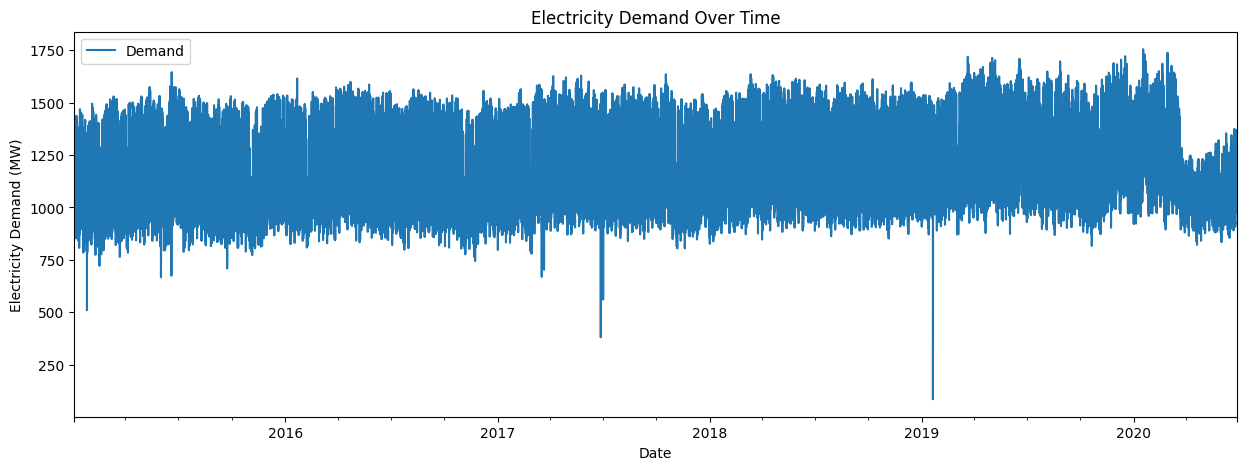

In [9]:
# Electricity demand over time
Train_data['datetime'] = pd.to_datetime(Train_data['datetime'])
Train_data.plot(x="datetime",y="nat_demand",label ="Demand",figsize=(15,5))
plt.title('Electricity Demand Over Time')
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.show()

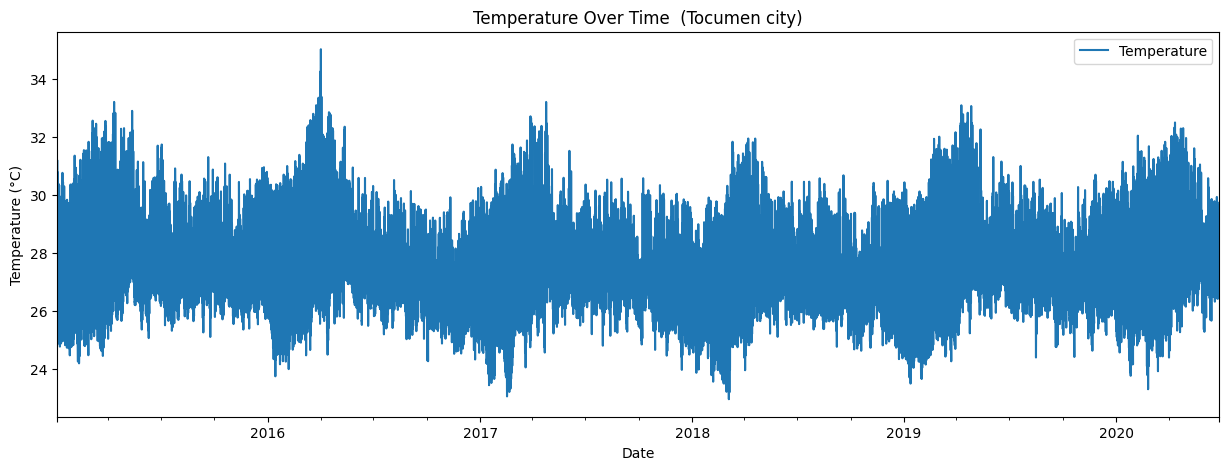

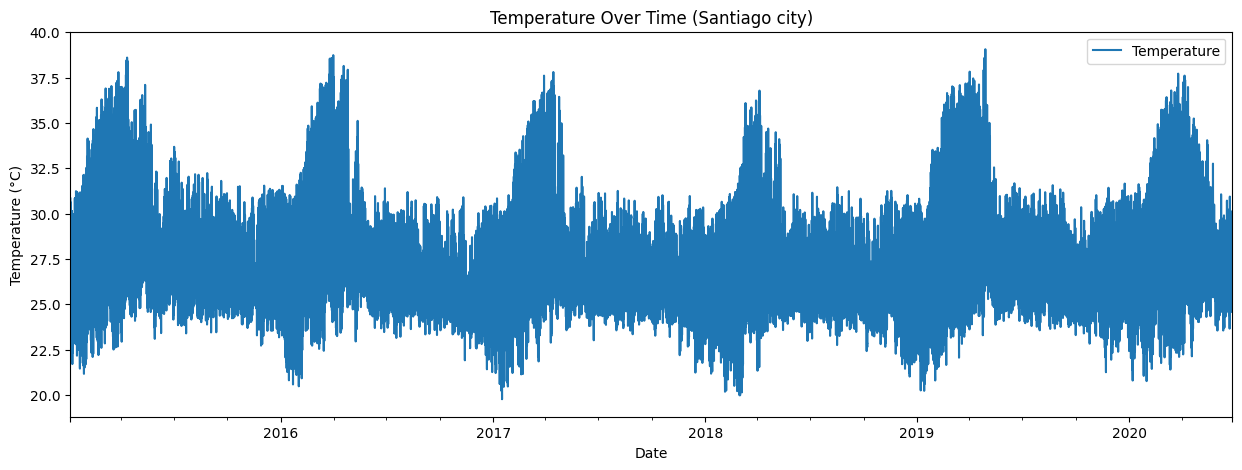

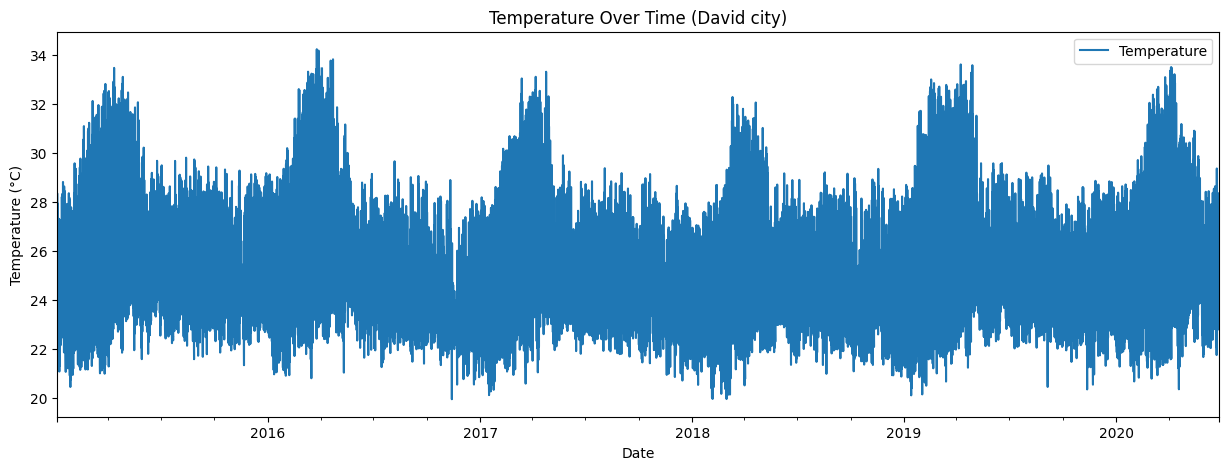

In [10]:
# Temperature over time
Train_data.plot(x="datetime",y="T2M_toc",label ="Temperature",figsize=(15,5))
plt.title('Temperature Over Time  (Tocumen city)')
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()

Train_data.plot(x="datetime",y="T2M_san",label ="Temperature",figsize=(15,5))
plt.title('Temperature Over Time (Santiago city)')
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()

Train_data.plot(x="datetime",y="T2M_dav",label ="Temperature",figsize=(15,5))
plt.title('Temperature Over Time (David city)')
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.show()



In [11]:
Train_data_demand_extract.T2M_toc = Train_data_demand_extract.T2M_toc.astype(int)
Train_data_demand_extract.T2M_san = Train_data_demand_extract.T2M_san.astype(int)
Train_data_demand_extract.T2M_dav = Train_data_demand_extract.T2M_dav.astype(int)

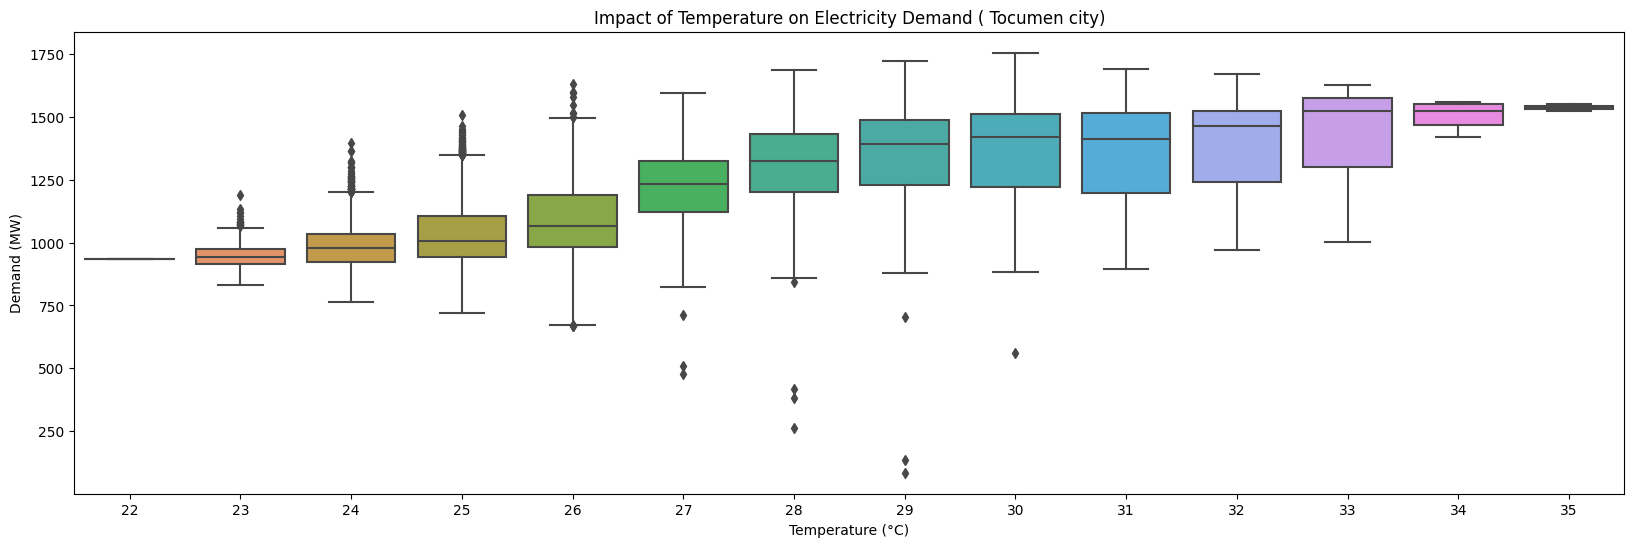

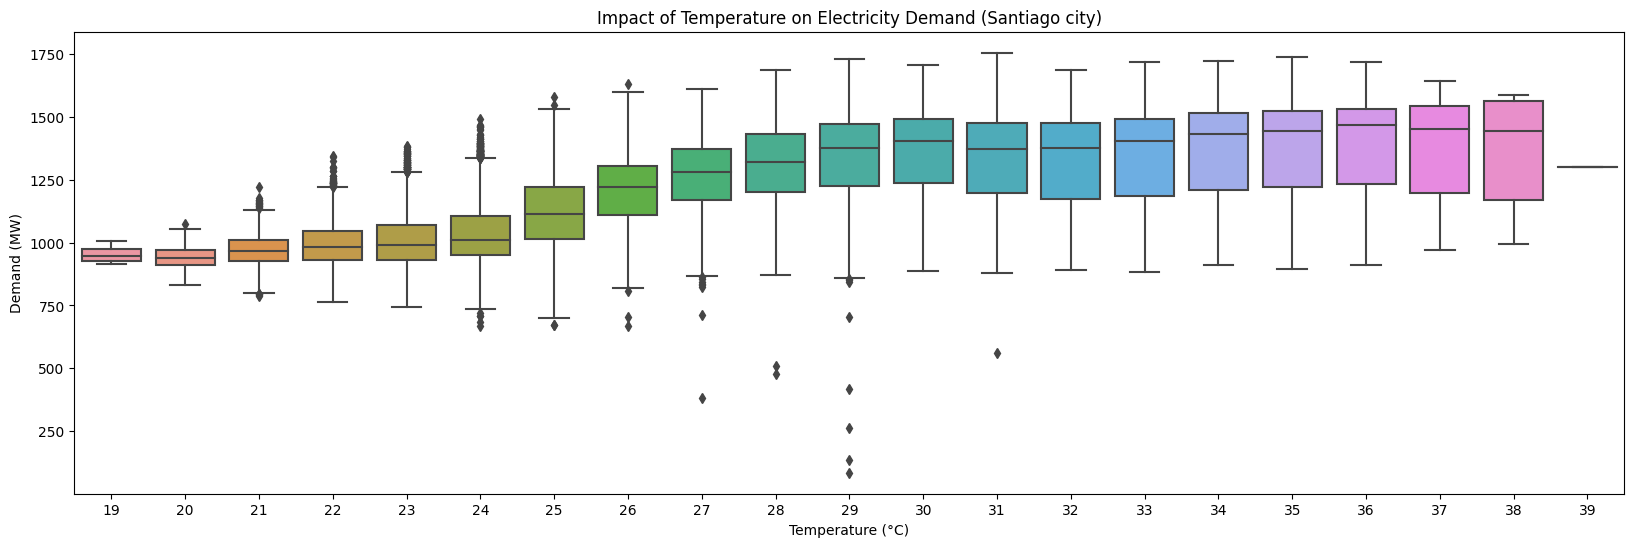

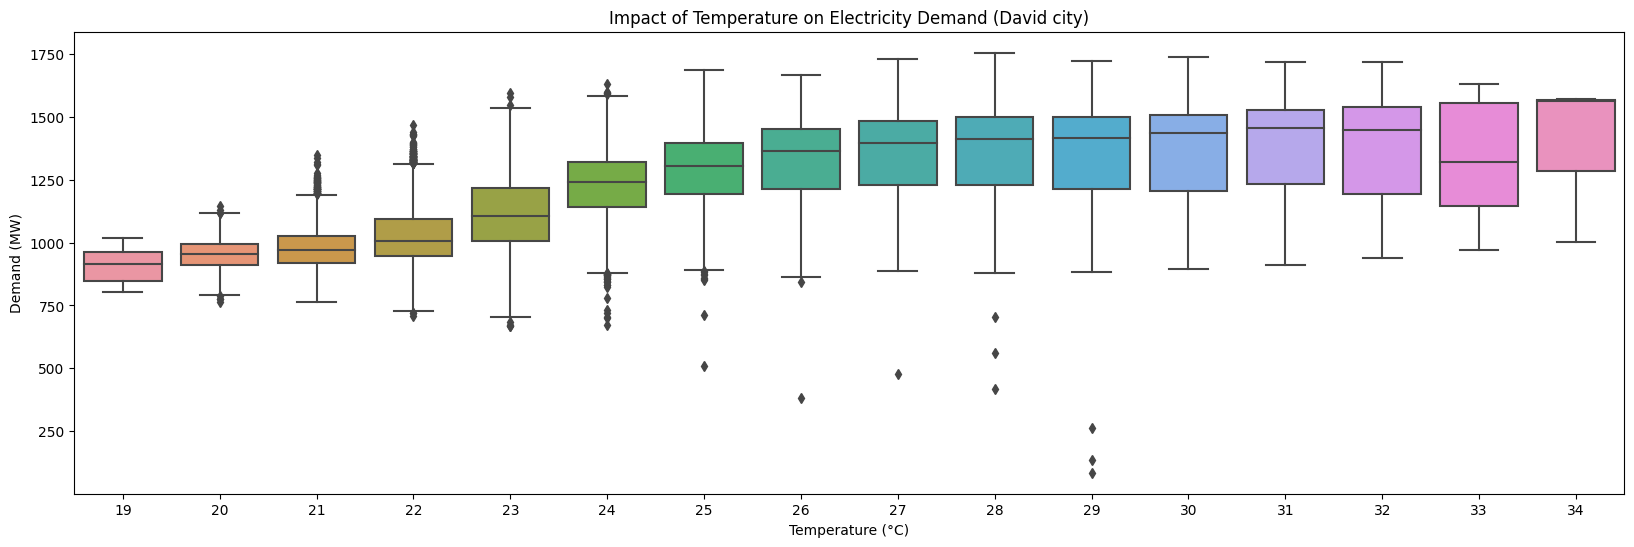

In [12]:
# Impact of Temperature on Electricity Demand
plt.figure(figsize=(20, 6))
sns.boxplot(x='T2M_toc', y='nat_demand', data=Train_data_demand_extract)
plt.title('Impact of Temperature on Electricity Demand ( Tocumen city)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Demand (MW)')
plt.show()

# Impact of Temperature on Electricity Demand
plt.figure(figsize=(20, 6))
sns.boxplot(x='T2M_san', y='nat_demand', data=Train_data_demand_extract)
plt.title('Impact of Temperature on Electricity Demand (Santiago city)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Demand (MW)')
plt.show()

# Impact of Temperature on Electricity Demand
plt.figure(figsize=(20, 6))
sns.boxplot(x='T2M_dav', y='nat_demand', data=Train_data_demand_extract)
plt.title('Impact of Temperature on Electricity Demand (David city)')
plt.xlabel('Temperature (°C)')
plt.ylabel('Demand (MW)')
plt.show()

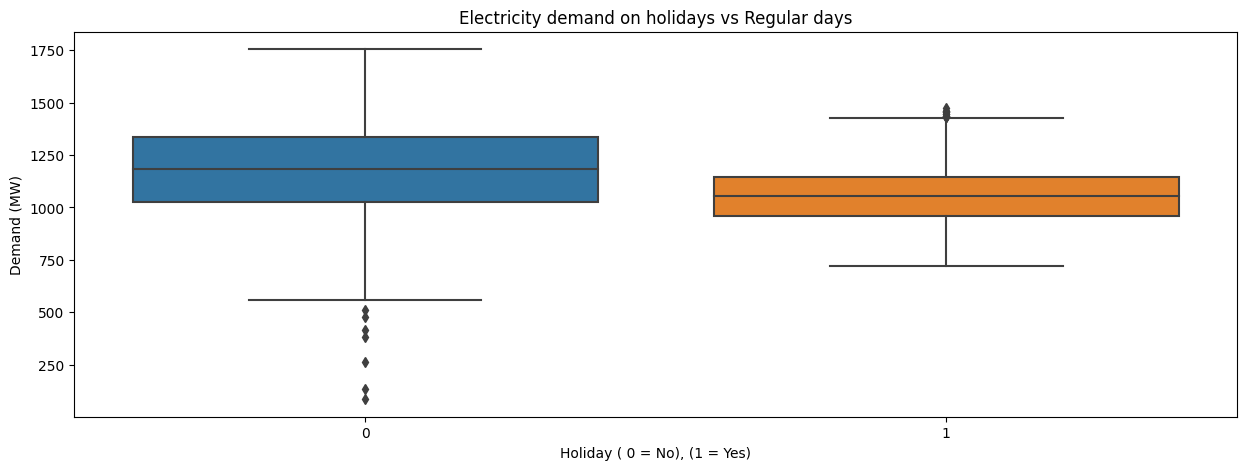

In [13]:
# demand during holidays 
plt.figure(figsize=(15, 5))
sns.boxplot(x='holiday', y='nat_demand', data=Train_data)
plt.title('Electricity demand on holidays vs Regular days')
plt.xlabel('Holiday ( 0 = No), (1 = Yes)')
plt.ylabel('Demand (MW)')
plt.show()

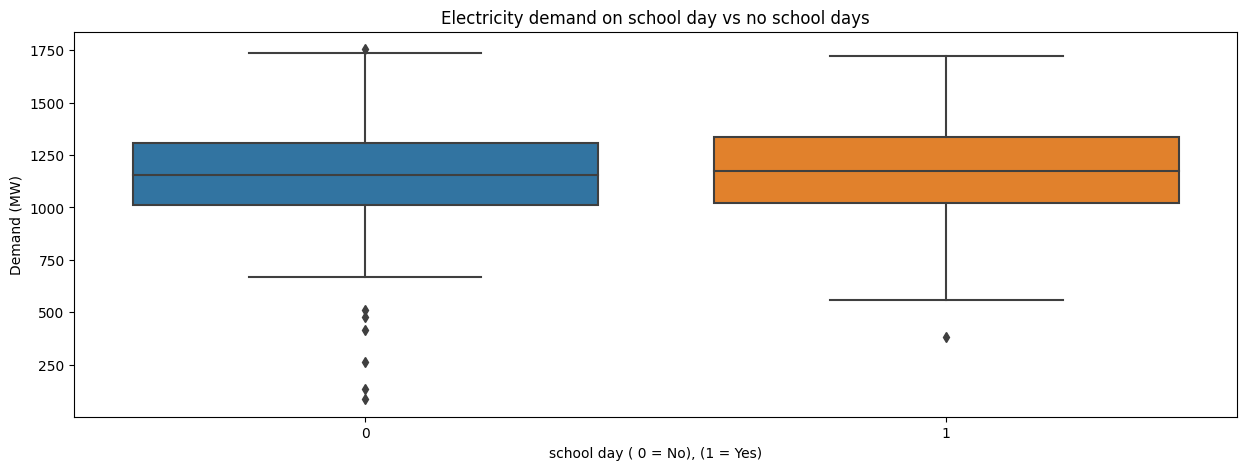

In [14]:
# demand during school days 
plt.figure(figsize=(15, 5))
sns.boxplot(x='school', y='nat_demand', data=Train_data)
plt.title('Electricity demand on school day vs no school days')
plt.xlabel('school day ( 0 = No), (1 = Yes)')
plt.ylabel('Demand (MW)')
plt.show()

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


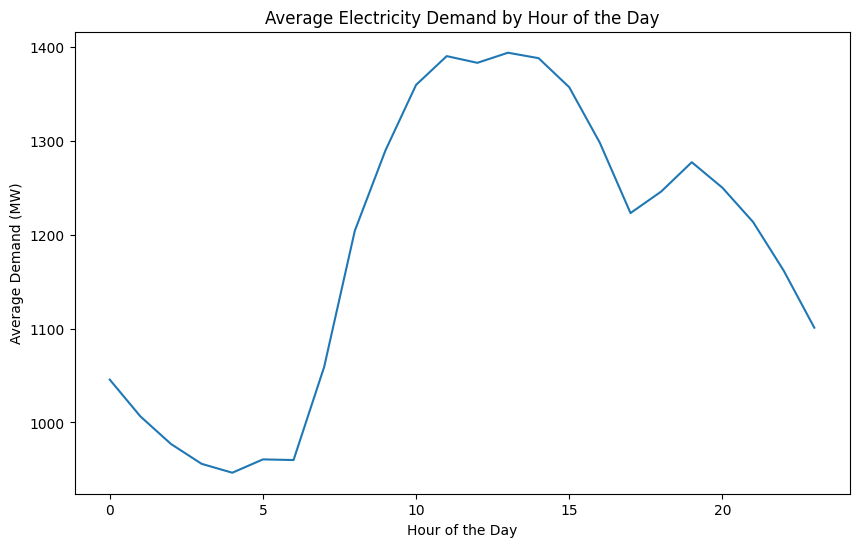

In [15]:
# Line plot of average load by hour of the day
plt.figure(figsize=(10, 6))
sns.lineplot(x='hourOfDay', y='DEMAND', data=week_data.groupby('hourOfDay').mean().reset_index())
plt.title('Average Electricity Demand by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Demand (MW)')
plt.show()

# **GRU-CNN Model**

# CNN

In [16]:
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, GRU, Dense, Dropout, concatenate
from tensorflow.keras.metrics import RootMeanSquaredError
import matplotlib.pyplot as plt


2024-08-12 22:43:11.989648: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-08-12 22:43:11.989785: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-08-12 22:43:12.170548: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [17]:
Train_data['datetime'] = pd.to_datetime(Train_data['datetime'])

# Set datetime as the index for resampling
Train_data.set_index('datetime', inplace=True)

# Resample the data to weekly mean based on 'nat_demand'
data_resampled = Train_data.resample('H').mean().reset_index()


/tmp/ipykernel_18/622772929.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  data_resampled = Train_data.resample('H').mean().reset_index()


In [18]:
data_resampled

,datetime,nat_demand,T2M_toc,QV2M_toc,TQL_toc,W2M_toc,T2M_san,QV2M_san,TQL_san,W2M_san,T2M_dav,QV2M_dav,TQL_dav,W2M_dav,Holiday_ID,holiday,school
0,2015-01-03 01:00:00,970.3450,25.865259,0.018576,0.016174,21.850546,23.482446,0.017272,0.001855,10.328949,22.662134,0.016562,0.096100,5.364148,0.0,0.0,0.0
1,2015-01-03 02:00:00,912.1755,25.899255,0.018653,0.016418,22.166944,23.399255,0.017265,0.001327,10.681517,22.578943,0.016509,0.087646,5.572471,0.0,0.0,0.0
2,2015-01-03 03:00:00,900.2688,25.937280,0.018768,0.015480,22.454911,23.343530,0.017211,0.001428,10.874924,22.531030,0.016479,0.078735,5.871184,0.0,0.0,0.0
3,2015-01-03 04:00:00,889.9538,25.957544,0.018890,0.016273,22.110481,23.238794,0.017128,0.002599,10.518620,22.512231,0.016487,0.068390,5.883621,0.0,0.0,0.0
4,2015-01-03 05:00:00,893.6865,25.973840,0.018981,0.017281,21.186089,23.075403,0.017059,0.001729,9.733589,22.481653,0.016456,0.064362,5.611724,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48043,2020-06-26 20:00:00,1128.5592,27.246545,0.020303,0.055511,9.289304,25.715295,0.019746,0.121552,1.990773,23.746545,0.018381,0.150879,2.444658,0.0,0.0,1.0
48044,2020-06-26 21:00:00,1112.7488,27.099573,0.020395,0.053848,9.837504,25.552698,0.019632,0.153870,2.094459,23.693323,0.018320,0.156311,2.515814,0.0,0.0,1.0
48045,2020-06-26 22:00:00,1081.5680,26.971155,0.020448,0.057251,10.262464,25.393030,0.019518,0.144531,2.396369,23.658655,0.018327,0.153259,2.800717,0.0,0.0,1.0
48046,2020-06-26 23:00:00,1041.6240,26.867487,0.020464,0.064178,10.326567,25.258112,0.019403,0.108063,2.720871,23.601862,0.018358,0.152771,3.138132,0.0,0.0,1.0


In [19]:

start_time = time.time()  # Record start time



# Select the features and label
features = data_resampled[['QV2M_toc', 'TQL_toc', 'W2M_toc','QV2M_san','TQL_san','W2M_san','QV2M_dav','TQL_dav','W2M_dav','datetime']]
labels = data_resampled['nat_demand']

# Convert datetime to numerical values (e.g., timestamp)
features['datetime'] = pd.to_datetime(features['datetime']).astype(int) / 10**9

# Handle missing values
features = features.fillna(method='ffill')

# Scale the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Reshape the data to 3D for CNN input (samples, timesteps, features)
# Here, we'll assume timesteps = 1 for simplicity
X = features_scaled.reshape(features_scaled.shape[0], 1, features_scaled.shape[1])
y = labels.values

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Build the CNN model
model = Sequential([
    Conv1D(filters=64, kernel_size=1, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    MaxPooling1D(pool_size=1),
    Flatten(),
    Dense(100, activation='relu'),
    Dropout(0.5),
    Dense(1)
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=[RootMeanSquaredError()])

# Train the model
history = model.fit(X_train, y_train, epochs=200, validation_data=(X_test, y_test), batch_size=1440)

# Evaluate the model
loss, rmse = model.evaluate(X_test, y_test)
print(f'Test Loss (MSE): {loss}')
print(f'Test RMSE: {rmse}')

end_time = time.time()  # Record end time

elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time:.4f} seconds")


/tmp/ipykernel_18/3399619356.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features['datetime'] = pd.to_datetime(features['datetime']).astype(int) / 10**9
/tmp/ipykernel_18/3399619356.py:13: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  features = features.fillna(method='ffill')
/opt/conda/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 1441663.1250 - root_mean_squared_error: 1200.6917 - val_loss: 1418274.2500 - val_root_mean_squared_error: 1190.9132
Epoch 2/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1425086.8750 - root_mean_squared_error: 1193.7692 - val_loss: 1398821.0000 - val_root_mean_squared_error: 1182.7177
Epoch 3/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1404518.1250 - root_mean_squared_error: 1185.1199 - val_loss: 1355722.2500 - val_root_mean_squared_error: 1164.3549
Epoch 4/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1352946.6250 - root_mean_squared_error: 1163.1510 - val_loss: 1275117.7500 - val_root_mean_squared_error: 1129.2111
Epoch 5/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1257371.5000 - root_mean_squared_error: 1121.3007 - val_loss: 1145877.5000 - val_root_mean_squared_error: 1070.4567
Epoch 6/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1117538.7500 - root_mean_squared_error: 1057.0651 - val_loss: 967

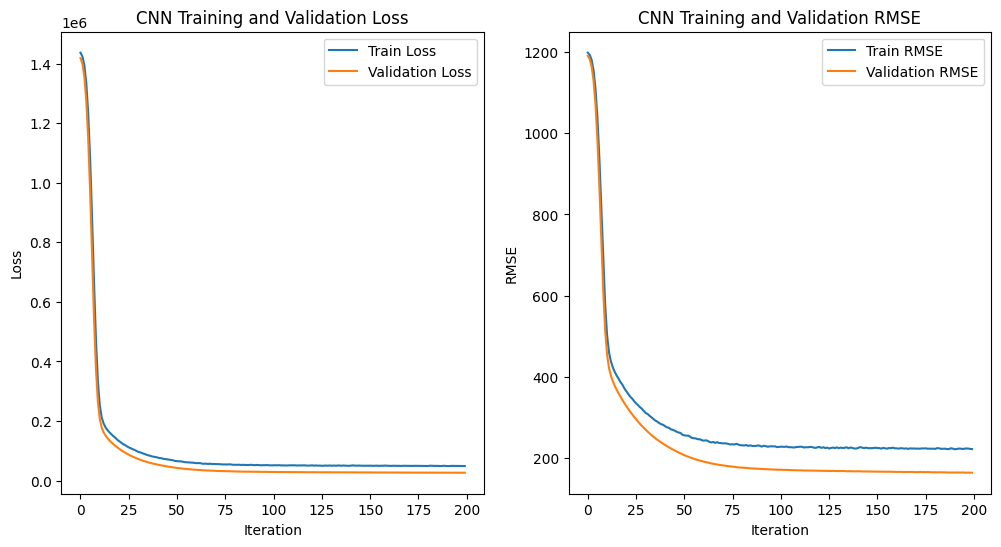

In [20]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('CNN Training and Validation Loss')
plt.legend()

# Plot training and validation RMSE
plt.subplot(1, 2, 2)
plt.plot(history.history['root_mean_squared_error'], label='Train RMSE')
plt.plot(history.history['val_root_mean_squared_error'], label='Validation RMSE')
plt.xlabel('Iteration')
plt.ylabel('RMSE')
plt.title('CNN Training and Validation RMSE')
plt.legend()

plt.show()



451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


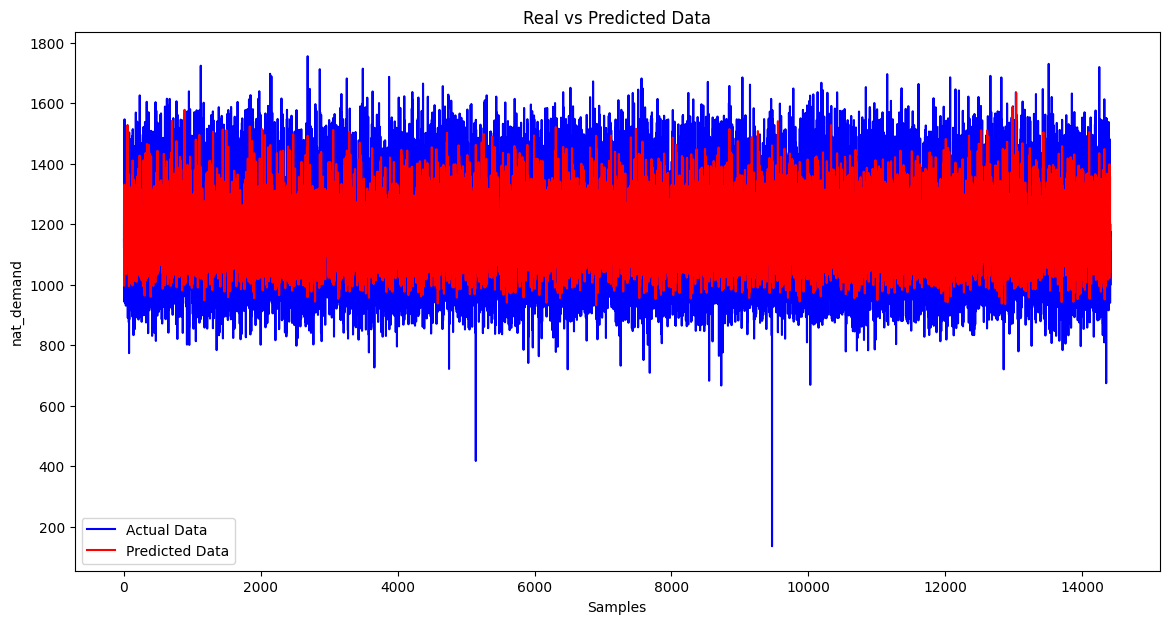

In [21]:
predictions = model.predict([X_test])
plt.figure(figsize=(14, 7))
plt.plot(y_test, color='blue', label='Actual Data')
plt.plot(predictions, color='red', label='Predicted Data')
plt.title('Real vs Predicted Data')
plt.xlabel('Samples')
plt.ylabel('nat_demand')
plt.legend()
plt.show()

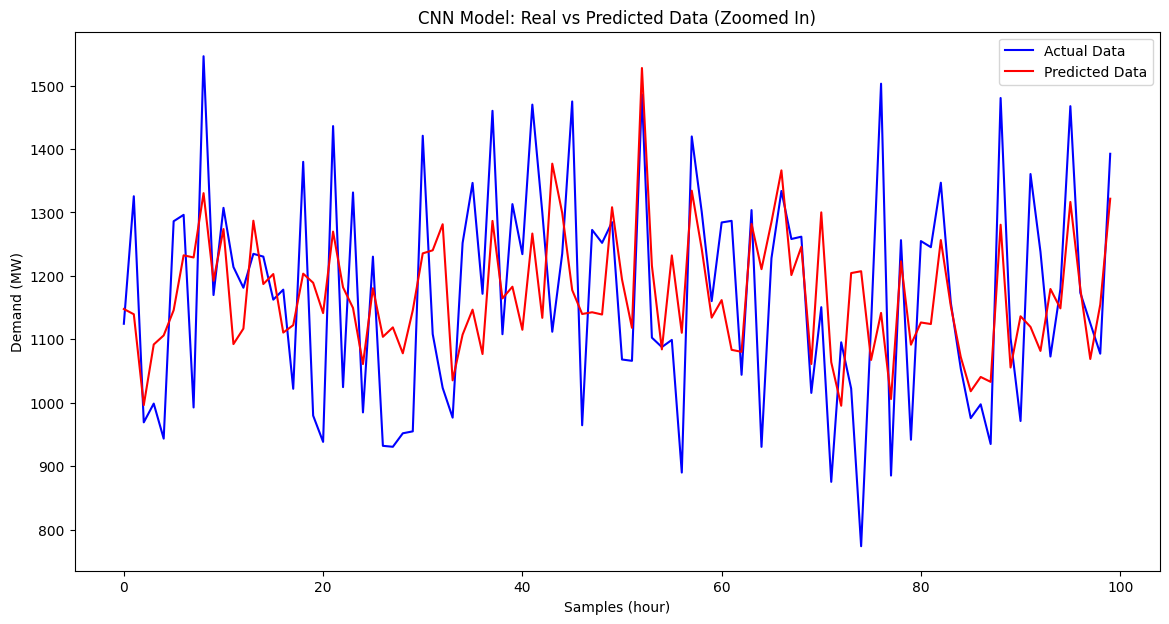

In [22]:
start_sample = 0
end_sample = 100

# Slice the test data and predictions
y_test_zoomed = y_test[start_sample:end_sample]
predictions_zoomed = predictions[start_sample:end_sample]

# Plot the zoomed-in data
plt.figure(figsize=(14, 7))
plt.plot(y_test_zoomed, color='blue', label='Actual Data')
plt.plot(predictions_zoomed, color='red', label='Predicted Data')
plt.title('CNN Model: Real vs Predicted Data (Zoomed In)')
plt.xlabel('Samples (hour)')
plt.ylabel('Demand (MW)')
plt.legend()
plt.show()


In [23]:
model.save('my_cnn_model.h5')

# GRU

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, GRU, Dense, Dropout, concatenate
from tensorflow.keras.metrics import RootMeanSquaredError
import matplotlib.pyplot as plt

In [25]:

start_time = time.time()  # Record start time

# Select the features and label
features = data_resampled[['QV2M_toc', 'TQL_toc', 'W2M_toc', 'QV2M_san', 'TQL_san', 'W2M_san', 'QV2M_dav', 'TQL_dav', 'W2M_dav','T2M_toc', 'T2M_san', 'T2M_dav', 'datetime']]
labels = data_resampled['nat_demand']

# Convert datetime to numerical values (e.g., timestamp)
features['datetime'] = pd.to_datetime(features['datetime']).astype(int) / 10**9

# Handle missing values
features = features.fillna(method='ffill')

# Scale the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Prepare data for GRU model (3D shape: samples, timesteps, features)
# Assuming we are treating each row as a separate sample with 1 timestep
X = features_scaled.reshape(features_scaled.shape[0], 1, features_scaled.shape[1])
y = labels.values

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Build the GRU model
model = Sequential([
    GRU(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1)
])

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=[RootMeanSquaredError()])

# Train the model
history = model.fit(X_train, y_train, epochs=200, validation_data=(X_test, y_test), batch_size=1440)

# Evaluate the model
loss, rmse = model.evaluate(X_test, y_test)
print(f'Test Loss (MSE): {loss}')
print(f'Test RMSE: {rmse}')

end_time = time.time()  # Record end time

elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time:.4f} seconds")


Epoch 1/200


/tmp/ipykernel_18/3840910469.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  features['datetime'] = pd.to_datetime(features['datetime']).astype(int) / 10**9
/tmp/ipykernel_18/3840910469.py:11: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  features = features.fillna(method='ffill')
/opt/conda/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 1439253.8750 - root_mean_squared_error: 1199.6886 - val_loss: 1424894.1250 - val_root_mean_squared_error: 1193.6893
Epoch 2/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1438385.6250 - root_mean_squared_error: 1199.3264 - val_loss: 1420777.5000 - val_root_mean_squared_error: 1191.9637
Epoch 3/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1434975.0000 - root_mean_squared_error: 1197.9028 - val_loss: 1410994.6250 - val_root_mean_squared_error: 1187.8529
Epoch 4/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1421960.0000 - root_mean_squared_error: 1192.4579 - val_loss: 1390050.3750 - val_root_mean_squared_error: 1179.0040
Epoch 5/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1397315.1250 - root_mean_squared_error: 1182.0746 - val_loss: 1350980.7500 - val_root_mean_squared_error: 1162.3170
Epoch 6/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1346065.3750 - root_mean_squared_error: 1160.1963 - val_loss: 1286979.62

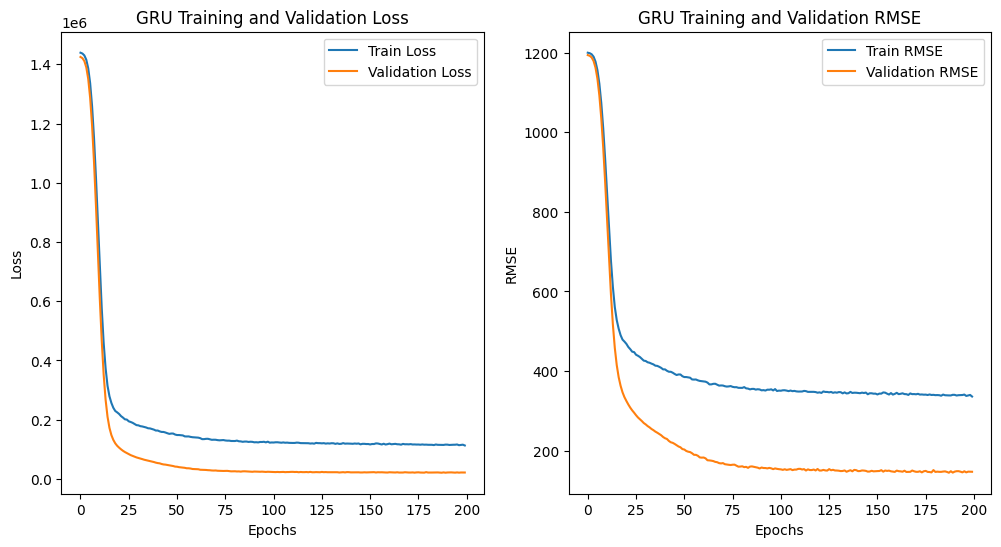

In [26]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('GRU Training and Validation Loss')
plt.legend()

# Plot training and validation RMSE
plt.subplot(1, 2, 2)
plt.plot(history.history['root_mean_squared_error'], label='Train RMSE')
plt.plot(history.history['val_root_mean_squared_error'], label='Validation RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.title('GRU Training and Validation RMSE')
plt.legend()

plt.show()

451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


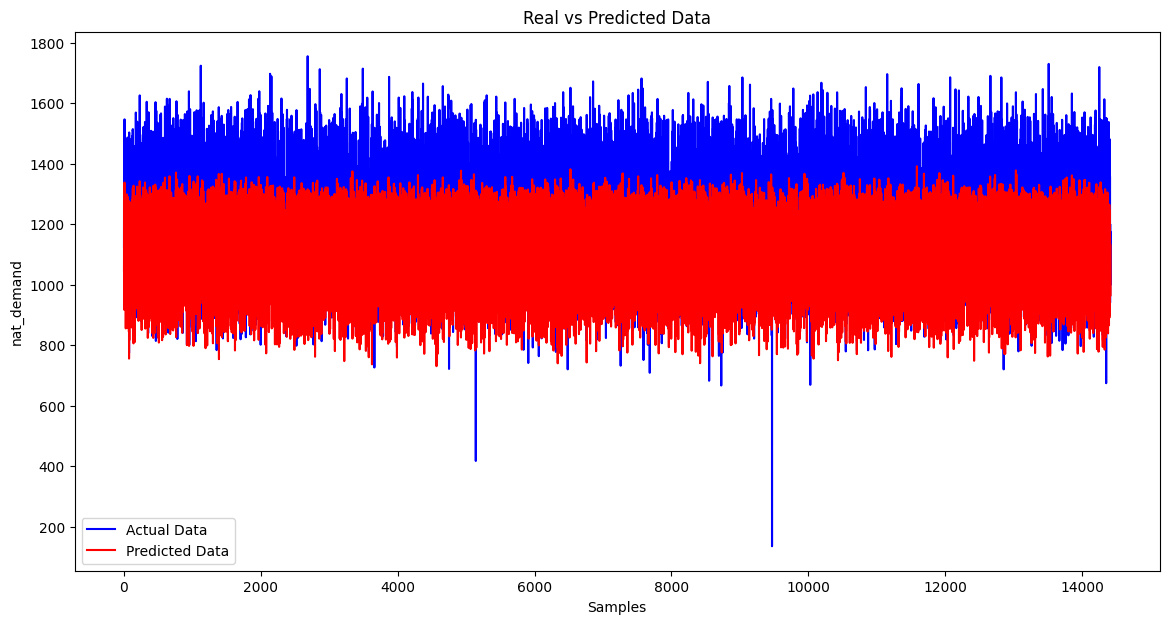

In [27]:
predictions = model.predict([X_test])
plt.figure(figsize=(14, 7))
plt.plot(y_test, color='blue', label='Actual Data')
plt.plot(predictions, color='red', label='Predicted Data')
plt.title('Real vs Predicted Data')
plt.xlabel('Samples')
plt.ylabel('nat_demand')
plt.legend()
plt.show()

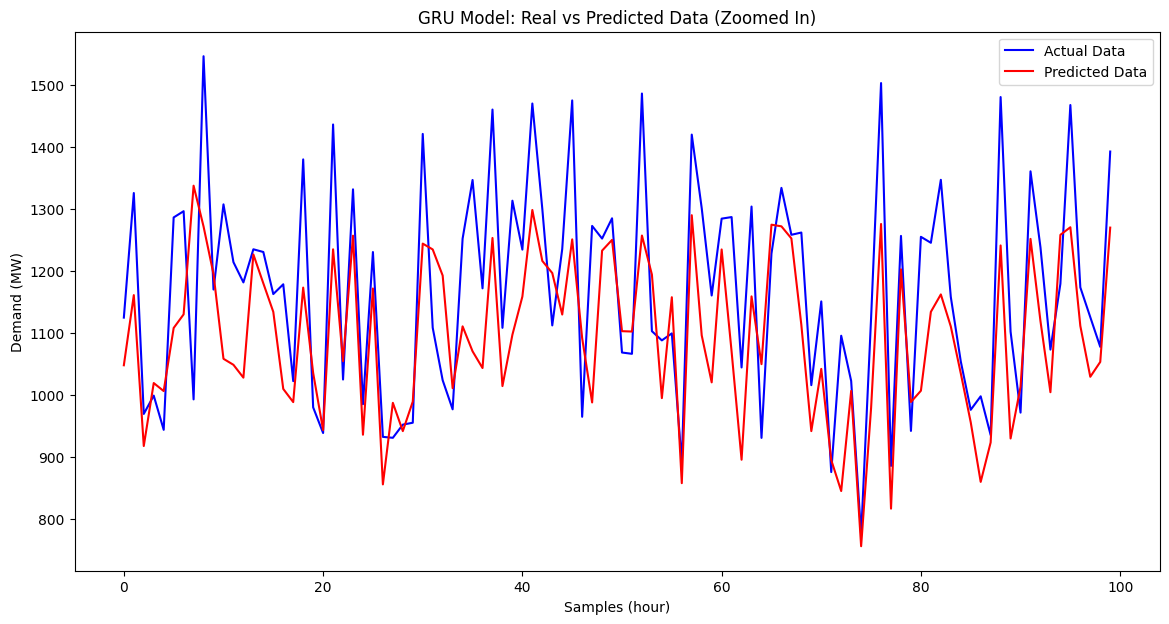

In [28]:
start_sample = 0
end_sample = 100

# Slice the test data and predictions
y_test_zoomed = y_test[start_sample:end_sample]
predictions_zoomed = predictions[start_sample:end_sample]

# Plot the zoomed-in data
plt.figure(figsize=(14, 7))
plt.plot(y_test_zoomed, color='blue', label='Actual Data')
plt.plot(predictions_zoomed, color='red', label='Predicted Data')
plt.title('GRU Model: Real vs Predicted Data (Zoomed In)')
plt.xlabel('Samples (hour)')
plt.ylabel('Demand (MW)')
plt.legend()
plt.show()


In [29]:
model.save('my_gru_model.h5')

# **GRU-CNN Model**

In [30]:

start_time = time.time()  # Record start time

# Select the features for CNN and GRU, and label
cnn_features = data_resampled[['QV2M_toc', 'TQL_toc', 'W2M_toc', 'QV2M_san', 'TQL_san', 'W2M_san', 'QV2M_dav', 'TQL_dav', 'W2M_dav', 'datetime']]
gru_features = data_resampled[['QV2M_toc', 'TQL_toc', 'W2M_toc', 'QV2M_san', 'TQL_san', 'W2M_san', 'QV2M_dav', 'TQL_dav', 'W2M_dav','T2M_toc', 'T2M_san', 'T2M_dav', 'datetime']]
labels = data_resampled['nat_demand']

# Convert datetime to numerical values 
cnn_features['datetime'] = pd.to_datetime(cnn_features['datetime']).astype(int) / 10**9
gru_features['datetime'] = pd.to_datetime(gru_features['datetime']).astype(int) / 10**9

# Handle missing values
cnn_features = cnn_features.fillna(method='ffill')
gru_features = gru_features.fillna(method='ffill')

# Scale the features
scaler_cnn = StandardScaler()
cnn_features_scaled = scaler_cnn.fit_transform(cnn_features)

scaler_gru = StandardScaler()
gru_features_scaled = scaler_gru.fit_transform(gru_features)

# Prepare data for CNN 
X_cnn = cnn_features_scaled.reshape(cnn_features_scaled.shape[0], 1, cnn_features_scaled.shape[1])
# Prepare data for GRU 
X_gru = gru_features_scaled.reshape(gru_features_scaled.shape[0], 1, gru_features_scaled.shape[1])
y = labels.values

# Split the data
X_cnn_train, X_cnn_test, X_gru_train, X_gru_test, y_train, y_test = train_test_split(X_cnn, X_gru, y, test_size=0.3, random_state=42)

# Input layers
input_cnn = Input(shape=(X_cnn_train.shape[1], X_cnn_train.shape[2]))
input_gru = Input(shape=(X_gru_train.shape[1], X_gru_train.shape[2]))

# CNN branch
cnn = Conv1D(32, kernel_size=1, activation='relu')(input_cnn)
cnn = MaxPooling1D(pool_size=1)(cnn)
cnn = Conv1D(64, kernel_size=1, activation='relu')(cnn)
cnn = MaxPooling1D(pool_size=1)(cnn)
cnn = Flatten()(cnn)
cnn = Dense(128, activation='relu')(cnn)
# GRU branch
gru = GRU(64, activation='relu', return_sequences=True)(input_gru)
gru = Dropout(0.5)(gru)
gru = GRU(128, activation='relu', return_sequences=True)(gru)
gru = Dropout(0.5)(gru)
gru = GRU(256, activation='relu')(gru)
gru = Dropout(0.5)(gru)

# Concatenate CNN and GRU outputs
concat = concatenate([cnn, gru])

# Fully connected layers
fc = Dense(64, activation='relu')(concat)
fc = Dropout(0.5)(fc)
fc = Dense(32, activation='relu')(fc)
fc = Dropout(0.5)(fc)
output_layer = Dense(1)(fc)

# Build the model
model = Model(inputs=[input_cnn, input_gru], outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error', metrics=[RootMeanSquaredError()])

# Train the model
history = model.fit([X_cnn_train, X_gru_train], y_train, epochs=200, validation_data=([X_cnn_test, X_gru_test], y_test), batch_size=1440)


end_time = time.time()  # Record end time

elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time:.4f} seconds")



/tmp/ipykernel_18/2507491361.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cnn_features['datetime'] = pd.to_datetime(cnn_features['datetime']).astype(int) / 10**9
/tmp/ipykernel_18/2507491361.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gru_features['datetime'] = pd.to_datetime(gru_features['datetime']).astype(int) / 10**9
/tmp/ipykernel_18/2507491361.py:13: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
 

Epoch 1/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - loss: 1436601.5000 - root_mean_squared_error: 1198.5823 - val_loss: 1402701.5000 - val_root_mean_squared_error: 1184.3571
Epoch 2/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 1342587.0000 - root_mean_squared_error: 1158.3777 - val_loss: 597957.1875 - val_root_mean_squared_error: 773.2769
Epoch 3/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - loss: 493086.4375 - root_mean_squared_error: 701.1130 - val_loss: 187181.1406 - val_root_mean_squared_error: 432.6443
Epoch 4/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 312763.0312 - root_mean_squared_error: 559.1924 - val_loss: 108363.7969 - val_root_mean_squared_error: 329.1866
Epoch 5/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 257003.1094 - root_mean_squared_error: 506.9012 - val_loss: 77204.0469 - val_root_mean_squared_error: 277.8562
Epoch 6/200
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - loss: 218760.9062 - root_mean_squared_error: 467.6803 - val_loss: 69986.1406 - 

In [31]:
loss, rmse = model.evaluate([X_cnn_test, X_gru_test], y_test)
print(f'Root Mean Squared Error (RMSE): {rmse}')

451/451 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 25994.1250 - root_mean_squared_error: 161.2075
Root Mean Squared Error (RMSE): 161.94793701171875


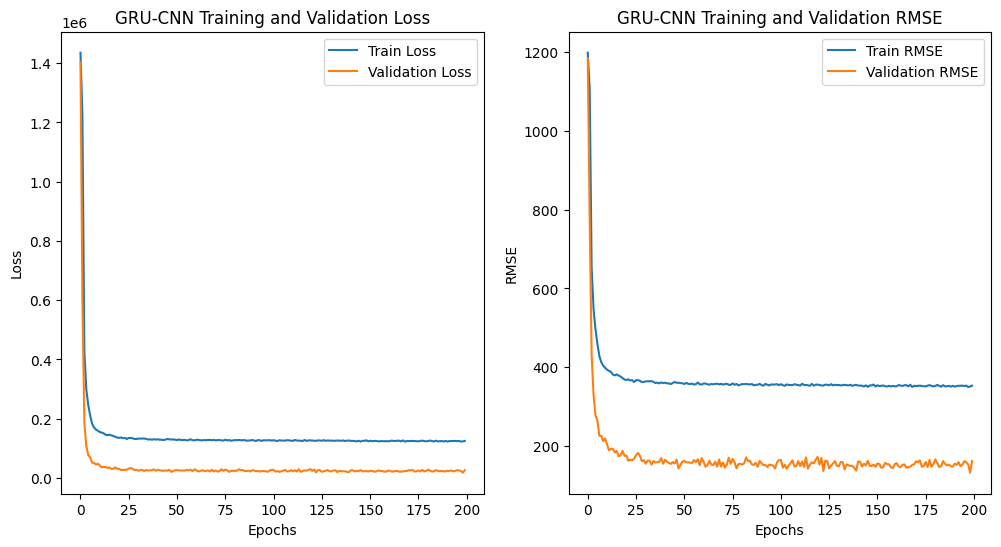

In [32]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('GRU-CNN Training and Validation Loss')
plt.legend()

# Plot training and validation RMSE
plt.subplot(1, 2, 2)
plt.plot(history.history['root_mean_squared_error'], label='Train RMSE')
plt.plot(history.history['val_root_mean_squared_error'], label='Validation RMSE')
plt.xlabel('Epochs')
plt.ylabel('RMSE')
plt.title('GRU-CNN Training and Validation RMSE')
plt.legend()

plt.show()

In [33]:
# Make predictions on the test data
predictions = model.predict([X_cnn_test, X_gru_test])

451/451 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


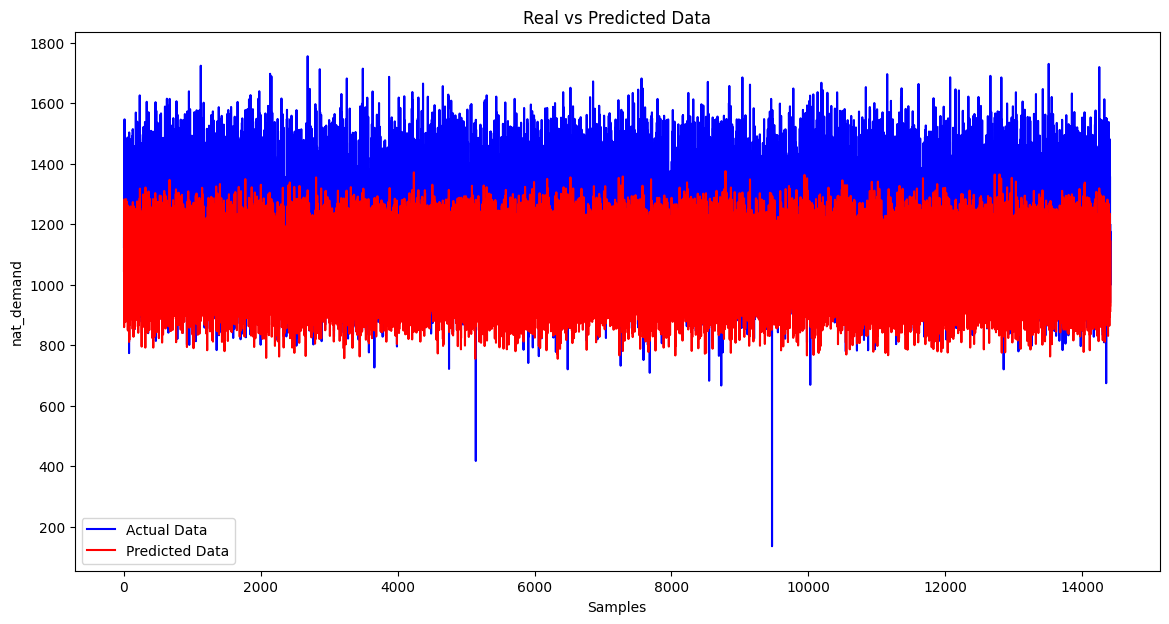

In [34]:
plt.figure(figsize=(14, 7))
plt.plot(y_test, color='blue', label='Actual Data')
plt.plot(predictions, color='red', label='Predicted Data')
plt.title('Real vs Predicted Data')
plt.xlabel('Samples')
plt.ylabel('nat_demand')
plt.legend()
plt.show()

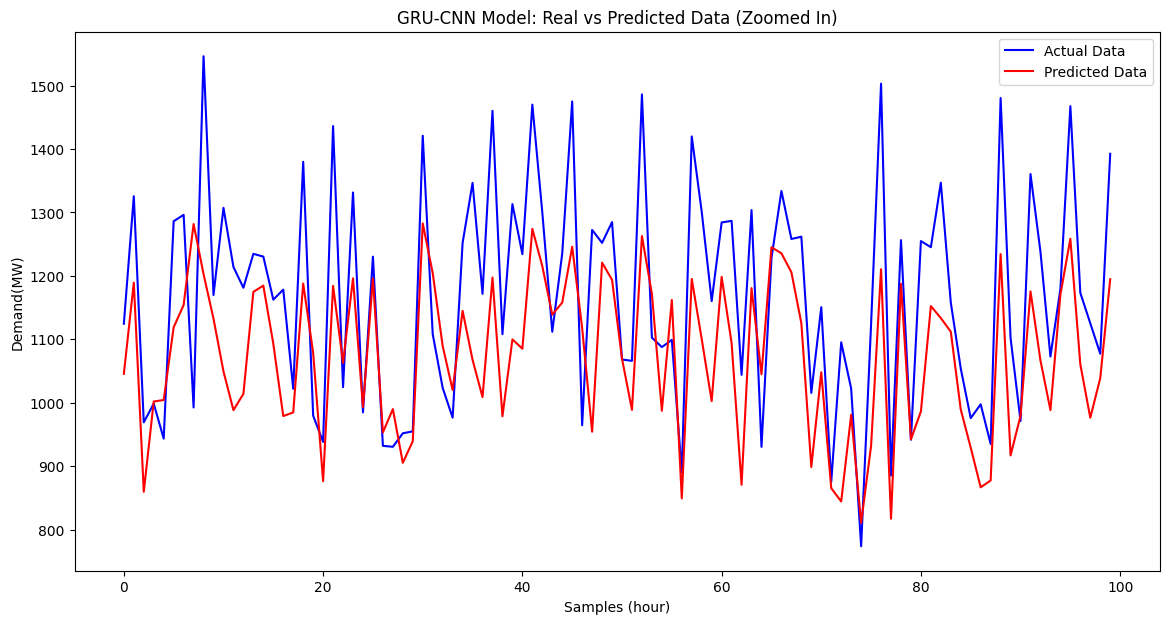

In [35]:
start_sample = 0
end_sample = 100

# Slice the test data and predictions
y_test_zoomed = y_test[start_sample:end_sample]
predictions_zoomed = predictions[start_sample:end_sample]

# Plot the zoomed-in data
plt.figure(figsize=(14, 7))
plt.plot(y_test_zoomed, color='blue', label='Actual Data')
plt.plot(predictions_zoomed, color='red', label='Predicted Data')
plt.title('GRU-CNN Model: Real vs Predicted Data (Zoomed In)')
plt.xlabel('Samples (hour)')
plt.ylabel('Demand(MW)')
plt.legend()
plt.show()


In [36]:
model.save('my_gru_cnn_model.h5')